In [1]:
# Number of particles
N = 100000

In [5]:
import numpy as np


# Particle orientations: uniformly random on the sphere
def random_unit_vectors(n):
    phi = np.random.uniform(0, 2*np.pi, n)
    costheta = np.random.uniform(-1, 1, n)
    theta = np.arccos(costheta)
    x = np.sin(theta) * np.cos(phi)
    y = np.sin(theta) * np.sin(phi)
    z = np.cos(theta)
    return np.stack([x, y, z], axis=1)


# Size barrier: probability to pass
def p_size(s):
    mu, sigma = 14, 0.5
    return np.exp(-0.5 * ((s - mu)/sigma)**2) / (sigma * np.sqrt(2*np.pi))

# Orientation barrier: probability to pass
a = np.array([1, 0, 0])
def p_theta(theta_vecs):
    # |a . theta| for each particle
    dot_products = np.abs(theta_vecs @ a)
    probs=np.exp(-dot_products)
    # Normalize so max probability is 1
    return probs / probs.max()


# Particle sizes: uniform from 1 to 100 nm
sizes = np.random.uniform(1, 100, N)

orientations = random_unit_vectors(N)

# Simulate passing through barriers
size_pass = np.random.rand(N) < p_size(sizes)
orient_pass = np.random.rand(N) < p_theta(orientations)
final_pass = size_pass & orient_pass

print(f"Fraction passing size barrier: {size_pass.mean():.4f}")
print(f"Fraction passing orientation barrier: {orient_pass.mean():.4f}")
print(f"Fraction passing both barriers: {final_pass.mean():.4f}")

Fraction passing size barrier: 0.0105
Fraction passing orientation barrier: 0.6323
Fraction passing both barriers: 0.0064


Text(0.5, 1.0, 'Histogram of Particle Sizes')

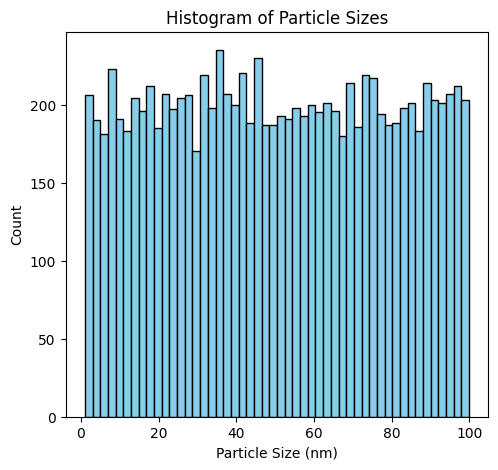

In [6]:
import matplotlib.pyplot as plt

# Histogram of particle sizes
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(sizes, bins=50, color='skyblue', edgecolor='black')
plt.xlabel('Particle Size (nm)')
plt.ylabel('Count')
plt.title('Histogram of Particle Sizes')

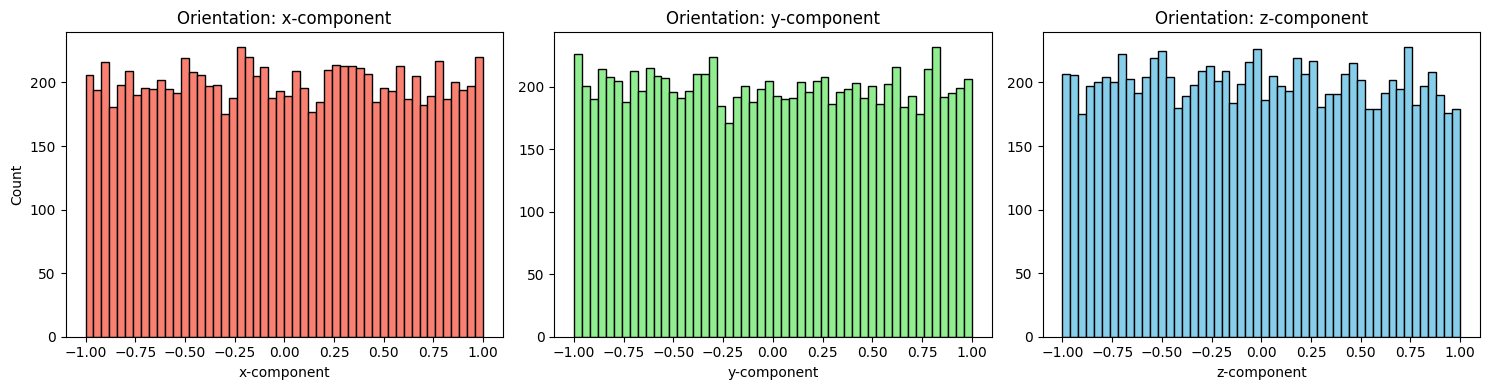

In [15]:
import matplotlib.pyplot as plt

# Extract x, y, z components
x_comp = orientations[:, 0]
y_comp = orientations[:, 1]
z_comp = orientations[:, 2]

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.hist(x_comp, bins=50, color='salmon', edgecolor='black')
plt.xlabel('x-component')
plt.ylabel('Count')
plt.title('Orientation: x-component')

plt.subplot(1, 3, 2)
plt.hist(y_comp, bins=50, color='lightgreen', edgecolor='black')
plt.xlabel('y-component')
plt.title('Orientation: y-component')

plt.subplot(1, 3, 3)
plt.hist(z_comp, bins=50, color='skyblue', edgecolor='black')
plt.xlabel('z-component')
plt.title('Orientation: z-component')

plt.tight_layout()
plt.show()

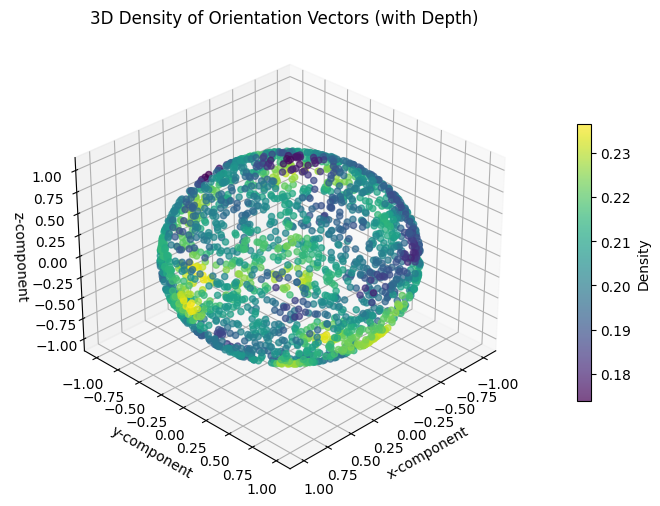

In [14]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.stats import gaussian_kde
import numpy as np

# Extract x, y, z components
x_comp = orientations[:, 0]
y_comp = orientations[:, 1]
z_comp = orientations[:, 2]

# Stack for KDE
xyz = np.vstack([x_comp, y_comp, z_comp])
kde = gaussian_kde(xyz)

# Plot 3D density (scatter colored by density, with depth effect)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

# Choose a viewing angle for depth
ax.view_init(elev=30, azim=45)

# Plot a scatter of points colored by density (for visual effect)
sample_idx = np.random.choice(x_comp.size, 2000, replace=False)
colors = kde(np.vstack([x_comp[sample_idx], y_comp[sample_idx], z_comp[sample_idx]]))
sc = ax.scatter(x_comp[sample_idx], y_comp[sample_idx], z_comp[sample_idx],
                c=colors, cmap='viridis', alpha=0.7, s=20, depthshade=True)

# Add color bar for density
cbar = fig.colorbar(sc, ax=ax, shrink=0.6, pad=0.1)
cbar.set_label('Density')

ax.set_xlabel('x-component')
ax.set_ylabel('y-component')
ax.set_zlabel('z-component')
ax.set_title('3D Density of Orientation Vectors (with Depth)')
plt.show()

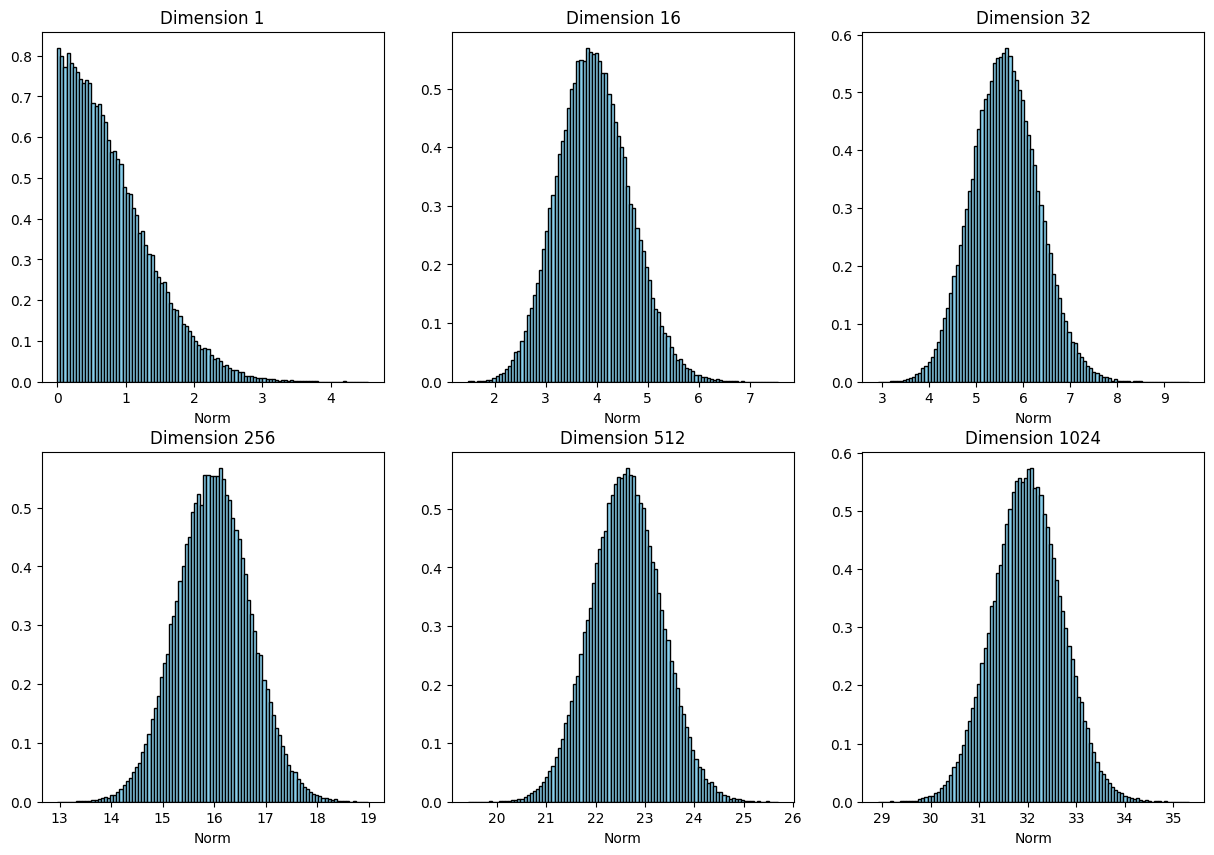

In [3]:
import numpy as np
import matplotlib.pyplot as plt

dims = [1, 16, 32, 256, 512, 1024]
plt.figure(figsize=(15, 10))

for i, d in enumerate(dims):
    # Generate N samples, each of dimension d
    samples = np.random.standard_normal((N, d))
    # Compute the Euclidean norm for each sample
    norms = np.linalg.norm(samples, axis=1)
    # Plot histogram of norms
    plt.subplot(2, 3, i+1)
    plt.hist(norms, bins=100, color='skyblue', edgecolor='black', density=True)
    plt.title(f'Dimension {d}')
    plt.xlabel('Norm')